# 特征维度、Token与Attention：从小矩阵开始

**记录日期：** 2026-11-14。目标是先理解向量维度和可学习投影，再逐步算出一次Attention；最后连接Depth Anything V2。配套 [可运行Notebook](token_embedding_attention.ipynb) 保存数值例子、图形和可修改的练习。

In [1]:
import os, sys, json, hashlib, math, importlib.util
from pathlib import Path
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
sys.dont_write_bytecode = True
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

torch.set_num_threads(4)
torch.manual_seed(0)
np.set_printoptions(precision=6, suppress=True)
MATERIAL_DIR = Path.cwd()
if not (MATERIAL_DIR / "token_embedding_attention.md").is_file():
    MATERIAL_DIR = MATERIAL_DIR / "01_foundations/learning"
assert (MATERIAL_DIR / "token_embedding_attention.md").is_file()
WORKSPACE_DIR = MATERIAL_DIR.parents[1]
ASSETS = MATERIAL_DIR / "assets"
ASSETS.mkdir(exist_ok=True)
print("Python:", sys.executable)
print("NumPy:", np.__version__, "Torch:", torch.__version__)
print("Examples: hand-designed/synthetic; CPU; no pretrained depth weights")

Python: d:\Conda\envs\torch_gpu_py310\python.exe
NumPy: 2.2.6 Torch: 2.11.0+cu128
Examples: hand-designed/synthetic; CPU; no pretrained depth weights


## 1. 为什么是384维

**384是这个ViT-Small的架构设置，即隐藏特征宽度，不是由图像尺寸或patch像素数唯一推导出来的。** 官方固定版本的`vit_small`明确写有`embed_dim=384`、`num_heads=6`。同一份代码中，Base、Large和Giant的宽度分别是768、1024和1536。

需要分开三个数字：

| 数字 | 由什么决定 | Depth Anything V2 Small例子 |
|---|---|---|
| patch输入长度 | patch高×宽×颜色通道 | $14\times14\times3=588$ |
| token特征宽度$C$ | 网络架构配置 | 384 |
| token数量$N$ | 图像中有多少个patch | $37\times37=1369$，适用于518×518输入 |

588个输入数经过一组可学习的权重，映射成384个输出数。**输出需要几个数，由架构决定；这些数具体怎样计算，由权重决定。** 训练更新权重的数值，并不把384自动训练成另一个维数。

原源码能确认这份模型使用384，不能据此证明384是所有任务的最优宽度。可以设计其他宽度，但相应投影、Attention、MLP等参数形状会改变，现成Small权重不能简单原样套用。

来源：[固定源码中的模型宽度](https://github.com/DepthAnything/Depth-Anything-V2/blob/a561b849ebae10a6f5ef49e26c83cbbcd36c71bf/depth_anything_v2/dinov2.py#L339-L415)。

## 2. 一个图块怎样变成向量

先用2×2灰度图块做手算，按行展平：

$$
P=\begin{bmatrix}1&2\\3&4\end{bmatrix},\qquad
x=\begin{bmatrix}1\\2\\3\\4\end{bmatrix}\in\mathbb R^4.
$$

这里每个输入数都有明确的像素位置。现在人为选两种测量方式：平均亮度，以及左右差异。将它们写成矩阵的两行：

$$
W_2=\begin{bmatrix}
\frac14&\frac14&\frac14&\frac14\\
-\frac12&\frac12&-\frac12&\frac12
\end{bmatrix}.
$$

那么：

$$
t_2=W_2x
=\begin{bmatrix}2.5\\1\end{bmatrix}\in\mathbb R^2.
$$

如果再加入一行，用于比较上下差异：

$$
W_3=\begin{bmatrix}
\frac14&\frac14&\frac14&\frac14\\
-\frac12&\frac12&-\frac12&\frac12\\
-\frac12&-\frac12&\frac12&\frac12
\end{bmatrix},\qquad
t_3=W_3x=\begin{bmatrix}2.5\\1\\2\end{bmatrix}\in\mathbb R^3.
$$

**输入始终是同样4个数，矩阵有几行，输出就有几维。** 本例中的特征由我们手工设计，真实网络则通过训练学习投影权重；不能将真实模型的384个通道都解释成事先规定好的边缘、纹理或某种物理量。

In [2]:
patch = np.array([[1., 2.], [3., 4.]])
x_patch = patch.reshape(-1)
W3 = np.array([[.25, .25, .25, .25],
               [-.5, .5, -.5, .5],
               [-.5, -.5, .5, .5]])
W2 = W3[:2].copy()
t2, t3 = W2 @ x_patch, W3 @ x_patch
print("Same input:", x_patch)
print("W2 shape:", W2.shape, "output:", t2)
print("W3 shape:", W3.shape, "output:", t3)
assert np.allclose(t2, [2.5, 1.])
assert np.allclose(t3, [2.5, 1., 2.])

Same input: [1. 2. 3. 4.]
W2 shape: (2, 4) output: [2.5 1. ]
W3 shape: (3, 4) output: [2.5 1.  2. ]


## 3. 从4→2的例子连接到588→384

对14×14的RGB patch，展平后的向量为$x\in\mathbb R^{588}$。Small的投影可写为：

$$
t=W_{\mathrm{emb}}x+b,\qquad
W_{\mathrm{emb}}\in\mathbb R^{384\times588},\quad
b\in\mathbb R^{384}.
$$

第$j$个输出为：

$$
t_j=\sum_{k=1}^{588}w_{jk}x_k+b_j,\quad j=1,\ldots,384.
$$

所以384个输出对应384组不同的加权组合。实际代码使用384个卷积核，每个核覆盖一个完整的14×14×3 patch，并在所有patch位置共享权重：

```text
Conv2d(in_channels=3, out_channels=384, kernel_size=14, stride=14)
```

卷积权重形状为`[384,3,14,14]`，展平后就是`[384,588]`。含bias时，这层有$384\times588+384=226176$个参数。本层每个patch产生384维特征，并不是产生384个深度值。

架构选择的384与可学习参数是两层概念。用一般损失$L$表示，训练会按梯度更新$W$和$b$；在维度已固定的情况下，更新的是矩阵元素。Notebook用一个单独的4→2教学目标展示一次梯度更新，不涉及真实深度训练。

### 列向量和按行存储的token矩阵

单个patch按列向量写成$t=Wx+b$。如果将$N$个patch按行叠为$X_p\in\mathbb R^{N\times588}$，同一变换应写为：

$$
T=X_pW_{\mathrm{emb}}^T+\mathbf1b^T\in\mathbb R^{N\times384}.
$$

转置来自存储约定改变，而不是另一个算法。后面Attention统一采用“每一行是一个token”的约定。

其中$\mathbf1$是长度为$N$的全1列向量，用于把同一个bias加到每一行。

来源：[PatchEmbed定义及forward](https://github.com/DepthAnything/Depth-Anything-V2/blob/a561b849ebae10a6f5ef49e26c83cbbcd36c71bf/depth_anything_v2/dinov2_layers/patch_embed.py#L26-L82)。

In [3]:
# One toy gradient update: change values, preserve the chosen dimensions.
x_grad = torch.tensor(x_patch, dtype=torch.float64)
W_grad = torch.tensor(W2, dtype=torch.float64, requires_grad=True)
pred_grad = W_grad @ x_grad
loss_before = .5 * pred_grad.square().sum()  # Artificial target [0,0].
gradient, = torch.autograd.grad(loss_before, W_grad)
assert torch.allclose(gradient, torch.outer(pred_grad.detach(), x_grad))
W_updated = W_grad.detach() - .01 * gradient
pred_updated = W_updated @ x_grad
loss_after = .5 * pred_updated.square().sum()
assert W_updated.shape == W_grad.shape == (2,4)
assert torch.allclose(pred_updated, torch.tensor([1.75,.7], dtype=torch.float64))
assert float(loss_after) < float(loss_before.detach())
print("Gradient:\n", gradient.numpy())
print("Chosen width remains 2; output:", pred_updated.numpy())
print("Toy loss:", float(loss_before.detach()), "->", float(loss_after))

Gradient:
 [[ 2.5  5.   7.5 10. ]
 [ 1.   2.   3.   4. ]]
Chosen width remains 2; output: [1.75 0.7 ]
Toy loss: 3.625 -> 1.7762499999999999


In [4]:
# Conv2d patch projection equals shared linear projection of unfolded patches.
images = torch.linspace(-1, 1, 2*3*28*42, dtype=torch.float64).reshape(2,3,28,42)
projection = torch.nn.Conv2d(3,384,kernel_size=14,stride=14).double()
with torch.no_grad():
    projected_map = projection(images)
    conv_tokens = projected_map.flatten(2).transpose(1,2)
    unfolded = F.unfold(images,kernel_size=14,stride=14)  # [B,588,N]
    matrix_tokens = (projection.weight.flatten(1) @ unfolded
                     + projection.bias[None,:,None]).transpose(1,2)
projection_max_error = float((conv_tokens-matrix_tokens).abs().max())
assert projected_map.shape == (2,384,2,3)
assert conv_tokens.shape == matrix_tokens.shape == (2,6,384)
assert torch.allclose(conv_tokens,matrix_tokens,rtol=1e-11,atol=1e-11)
assert sum(p.numel() for p in projection.parameters()) == 226176
print("Kernel:", tuple(projection.weight.shape))
print("Map -> tokens:", tuple(projected_map.shape), "->", tuple(conv_tokens.shape))
print("Conv/linear max difference:", projection_max_error)

Kernel: (384, 3, 14, 14)
Map -> tokens: (2, 384, 2, 3) -> (2, 6, 384)
Conv/linear max difference: 1.2490009027033011e-15


## 4. Token数量与特征维度不要混淆

令$X\in\mathbb R^{N\times C}$，每行是一个token，每列是一个特征坐标。

- $N$回答“有多少个位置”。
- $C$回答“每个位置用多少个数表示”。

例如`[1369,384]`表示1369个patch位置，每个位置一个384维向量。图像尺寸变化、patch大小不变时，$N$可以改变而$C$不变。模型从Small换为Base时，$C$可以改变，而同一图像与patch设置下的$N$仍可相同。

多图输入再增加batch维，写为`[B,N,C]`。在本文实际Small例子中，CLS参与编码器计算，因而Attention中的$N$是1370；之后取出patch特征时才回到1369。

In [5]:
for height,width in [(518,518),(518,686)]:
    assert height%14 == width%14 == 0
    n = (height//14)*(width//14)
    print(f"{height}x{width}: {n} patch tokens, width C=384; with CLS N={n+1}")
assert 37*37 == 1369 and 37*49 == 1813

518x518: 1369 patch tokens, width C=384; with CLS N=1370
518x686: 1813 patch tokens, width C=384; with CLS N=1814


## 5. Attention要解决什么问题

patch投影先分别编码各个图块。要理解整个图像，一个位置的表示还可能需要结合其他位置的信息。Attention提供一种**随当前输入变化的加权聚合方式**。

对查询位置$i$，它会形成对各个候选位置$j$的权重$a_{ij}$，再聚合这些位置提供的向量$v_j$：

$$
o_i=\sum_{j=1}^{N}a_{ij}v_j.
$$

这里的$o_i$仍是特征向量，不是自动变成物体类别或深度。它的作用取决于所处网络、后续层和训练监督。

下面只讨论**无mask、无dropout的单头scaled dot-product self-attention**。后续再增加多头与完整Transformer块。

## 6. Q、K、V分别是什么

输入为$X\in\mathbb R^{N\times C}$，通过三组可学习映射得到：

$$
Q=XW_Q+b_Q,\quad K=XW_K+b_K,\quad V=XW_V+b_V.
$$

这里bias按行广播，并且：

$$
W_Q,W_K\in\mathbb R^{C\times d_k},\qquad
W_V\in\mathbb R^{C\times d_v}.
$$

| 名称 | 形状 | 在计算中的作用 |
|---|---|---|
| Query，$Q$ | $N\times d_k$ | 查询位置用于与各个Key计算关联分数 |
| Key，$K$ | $N\times d_k$ | 各位置用于参与匹配的表示 |
| Value，$V$ | $N\times d_v$ | 依据权重实际被聚合的内容 |

“Query表示我需要什么、Key表示我能匹配什么、Value表示我提供什么”可以作为直觉，但这些语义并非人工写死在某一维里。真正执行的是可学习投影、点积与加权求和。

**可学习参数是$W_Q,W_K,W_V$及bias；$Q,K,V$是当前输入算出的中间结果。** 换一张图，参数可保持不变，而$Q,K,V$和注意力权重会变化。

self-attention表示三者都来自同一个输入$X$，不表示$Q=K=V$。cross-attention则可以让$Q$来自一组特征、$K,V$来自另一组。

下一节用人为指定的简单投影手算。示例故意令$Q=K$，方便算数；真实模型不受这一限制。

## 7. 完整手算一次Attention

### 7.1 准备三个token

选取3个二维token，并人为设置投影：

$$
X=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\quad
W_Q=W_K=I_2,\quad W_V=10I_2.
$$

于是：

$$
Q=K=X,\qquad
V=\begin{bmatrix}10&0\\0&10\\10&10\end{bmatrix}.
$$

这是用于看清计算的教学例子，数值不代表真实网络学到的语义或深度。

In [6]:
X = np.array([[1.,0.],[0.,1.],[1.,1.]])
WQ, WK, WV = np.eye(2), np.eye(2), 10*np.eye(2)
Q, K, V = X@WQ, X@WK, X@WV
print("Q:\n",Q,"\nK:\n",K,"\nV:\n",V)
assert Q.shape == K.shape == V.shape == (3,2)

Q:
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 
K:
 [[1. 0.]
 [0. 1.]
 [1. 1.]] 
V:
 [[10.  0.]
 [ 0. 10.]
 [10. 10.]]


### 7.2 点积：每个Query与全部Key比较

$$
QK^T=\begin{bmatrix}
1&0&1\\0&1&1\\1&1&2
\end{bmatrix}.
$$

将单个query/key记为列向量$q_i,k_j$，则Q、K的相应行是$q_i^T,k_j^T$，$QK^T$的第$i$行、第$j$列是$q_i^Tk_j$。例如第一个Query为$[1,0]$，与三个Key的点积为$[1,0,1]$。所以它与Key1、Key3有相同分数，与Key2分数较低；它也可以关注自身。

点积可以为负，也会受到向量长度影响。没有另外进行单位范数归一化时，它不是余弦相似度，更不是物理距离或深度。

In [7]:
dot_scores = Q @ K.T
hand_dot = np.array([[sum(q[c]*k[c] for c in range(2)) for k in K] for q in Q])
assert np.allclose(dot_scores,hand_dot)
assert np.allclose(dot_scores,[[1,0,1],[0,1,1],[1,1,2]])
print("Rows are queries; columns are keys:\n",dot_scores)

Rows are queries; columns are keys:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]


### 7.3 除以$\sqrt{d_k}$：调整分数尺度

这里$d_k=2$：

$$
S=\frac{QK^T}{\sqrt2}
\approx\begin{bmatrix}
0.707107&0&0.707107\\
0&0.707107&0.707107\\
0.707107&0.707107&1.414214
\end{bmatrix}.
$$

这一步不改变矩阵形状，而是改变分数的数值范围。维数增大时，未经缩放的点积可能变得很大，使softmax过于集中。

一个有明确假设的解释是：若各维分量独立、$q$与$k$也相互独立，且各分量均值为0、方差为1，则$q^Tk$的方差为$d_k$，除以$\sqrt{d_k}$后方差为1。真实网络中的Q、K一般不满足这些独立条件，因此这是尺度设计的解释，不是对训练后特征分布的保证。

In [8]:
d_k = Q.shape[-1]
S = dot_scores / np.sqrt(d_k)
print("d_k:",d_k,"sqrt(d_k):",np.sqrt(d_k))
print("Scaled scores S:\n",S)

d_k: 2 sqrt(d_k): 1.4142135623730951
Scaled scores S:
 [[0.707107 0.       0.707107]
 [0.       0.707107 0.707107]
 [0.707107 0.707107 1.414214]]


In [9]:
# Check the variance explanation under its explicit iid assumptions.
rng_variance = np.random.default_rng(7)
variance_examples = []
for dimension in [2,64,256]:
    q_sample = rng_variance.normal(size=(10000,dimension))
    k_sample = rng_variance.normal(size=(10000,dimension))
    raw_dot = (q_sample*k_sample).sum(axis=1)
    raw_var,scaled_var = raw_dot.var(),(raw_dot/np.sqrt(dimension)).var()
    assert np.isclose(scaled_var,raw_var/dimension)
    variance_examples.append({"d_k":dimension,"raw_variance":float(raw_var),"scaled_variance":float(scaled_var)})
    print(f"d={dimension}: Var(dot)={raw_var:.3f}, Var(dot/sqrt(d))={scaled_var:.3f}")
del q_sample,k_sample,raw_dot

d=2: Var(dot)=1.963, Var(dot/sqrt(d))=0.982
d=64: Var(dot)=63.072, Var(dot/sqrt(d))=0.985


d=256: Var(dot)=252.591, Var(dot/sqrt(d))=0.987


### 7.4 对每一行做softmax

$$
a_{ij}=\frac{\exp(S_{ij})}{\sum_{\ell=1}^{N}\exp(S_{i\ell})},\qquad
A=\operatorname{softmax}_{\mathrm{row}}(S).
$$

每个Query有自己的归一化分母。第一行可手算为：

$$
[a_{11},a_{12},a_{13}]
\approx[0.401112,\ 0.197776,\ 0.401112].
$$

全部权重为：

$$
A\approx\begin{bmatrix}
0.401112&0.197776&0.401112\\
0.197776&0.401112&0.401112\\
0.248255&0.248255&0.503490
\end{bmatrix}.
$$

在本节无dropout的设置下，每一行非负且和为1；不要求每列和为1。即使本例$QK^T$对称，$A$也不对称，例如$a_{13}\ne a_{31}$。

为避免数值溢出，代码通常先减去每行最大值再取指数；softmax结果不变。这是数值稳定措施，不是另一个注意力定义。

In [10]:
def softmax_rows(logits):
    shifted = logits-logits.max(axis=-1,keepdims=True)
    exp_scores = np.exp(shifted)
    return exp_scores/exp_scores.sum(axis=-1,keepdims=True)

A = softmax_rows(S)
closed_form = 1/(2+np.exp(-1/np.sqrt(2)))
assert np.isclose(A[0,0],closed_form)
assert np.allclose(A.sum(axis=-1),1.) and (A>=0).all()
assert np.allclose(softmax_rows(S+np.array([[100.],[-3.],[7.]])),A)
assert not np.allclose(A,A.T)
print("Weights A:\n",A)
print("Row sums:",A.sum(axis=-1),"column sums:",A.sum(axis=0))

Weights A:
 [[0.401112 0.197776 0.401112]
 [0.197776 0.401112 0.401112]
 [0.248255 0.248255 0.50349 ]]
Row sums: [1. 1. 1.] column sums: [0.847143 0.847143 1.305714]


### 7.5 乘以V：按权重混合内容

$$
O=AV\in\mathbb R^{3\times2}.
$$

第一个输出是：

$$
o_1=0.401112[10,0]+0.197776[0,10]+0.401112[10,10]
\approx[8.022242,5.988879].
$$

全部输出约为：

$$
O\approx\begin{bmatrix}
8.022242&5.988879\\
5.988879&8.022242\\
7.517449&7.517449
\end{bmatrix}.
$$

显示的矩阵与权重已经舍入；Notebook使用未舍入数值计算，末位可能与直接乘显示数字略有不同。

**Q和K决定怎样分配权重，V提供被聚合的向量。** 分配权重后不是只选择一个token，而是可以同时混合多个位置的信息。输出仍有3个token，每个token为2维。

整理成一条计算链，就是：

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V.
$$


图中行对应Query、列对应Key；分数和权重使用各自色标。数值来自上述合成例子，图不是预训练模型的注意力可视化。

In [11]:
O = A@V
first_output = sum(A[0,j]*V[j] for j in range(3))
assert np.allclose(first_output,O[0])
assert O.shape == (3,2)
print("Output AV:\n",O)
print("First output from explicit weighted sum:",first_output)

q_t,k_t,v_t = [torch.tensor(a,dtype=torch.float64)[None,None] for a in [Q,K,V]]
torch_output = F.scaled_dot_product_attention(q_t,k_t,v_t,dropout_p=0.,is_causal=False)[0,0].numpy()
single_head_error = float(np.max(np.abs(O-torch_output)))
assert np.allclose(O,torch_output,rtol=1e-12,atol=1e-12)
print("NumPy / Torch SDPA max difference:",single_head_error)

Output AV:
 [[8.022242 5.988879]
 [5.988879 8.022242]
 [7.517449 7.517449]]
First output from explicit weighted sum: [8.022242 5.988879]
NumPy / Torch SDPA max difference: 8.881784197001252e-16


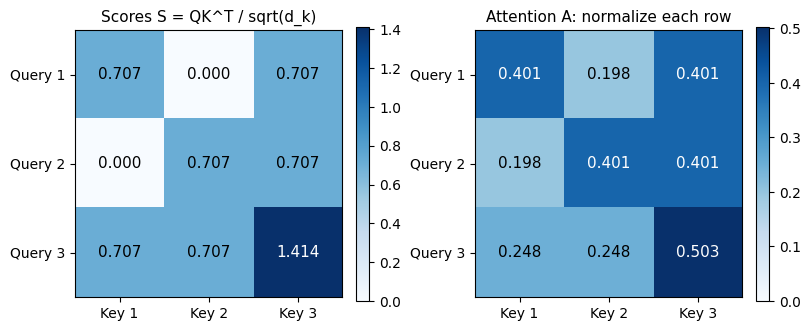

In [12]:
fig,axes = plt.subplots(1,2,figsize=(8,3.6),layout="constrained")
for ax,matrix,title in zip(axes,[S,A],["Scores S = QK^T / sqrt(d_k)","Attention A: normalize each row"]):
    image=ax.imshow(matrix,cmap="Blues",vmin=0)
    ax.set_xticks(range(3),["Key 1","Key 2","Key 3"])
    ax.set_yticks(range(3),["Query 1","Query 2","Query 3"])
    ax.set_title(title,fontsize=11)
    for i in range(3):
        for j in range(3):
            ax.text(j,i,f"{matrix[i,j]:.3f}",ha="center",va="center",fontsize=11,
                    color="white" if matrix[i,j]>.65*matrix.max() else "black")
    fig.colorbar(image,ax=ax,shrink=.78)
fig.savefig(ASSETS/"attention_scores_weights.png",dpi=150)
plt.show()

## 8. 用三个改动检查自己是否理解

1. **只改变V，保持Q和K不变。** 注意力权重A保持不变，输出O可以改变；所以权重与被混合内容是两件事。
2. **令所有V向量都一样。** 无论每行怎样分配权重，输出都会是同一个V向量；所以仅凭权重变化也不能断言最终输出一定变化。
3. **增大Q的幅度，保持K、V不变。** 分数幅度改变，softmax通常更集中；若最高分并列，仍可能将权重分给多个位置。


图只改变教学例子的Q幅度，观察第三个Query对三个Key的权重。配套Notebook可修改查询位置、Q幅度和V幅度，重新计算。

In [13]:
def attention_numpy(q,k,v):
    weights=softmax_rows(q@np.swapaxes(k,-2,-1)/np.sqrt(q.shape[-1]))
    return weights,weights@v

A_value,O_value=attention_numpy(Q,K,V*3)
assert np.allclose(A_value,A) and np.allclose(O_value,3*O)
constant_values=np.repeat([[2.,5.]],3,axis=0)
_,constant_output=attention_numpy(Q*3,K,constant_values)
assert np.allclose(constant_output,constant_values)
permutation=np.array([2,0,1])
A_permuted,O_permuted=attention_numpy(Q[permutation],K[permutation],V[permutation])
assert np.allclose(A_permuted,A[np.ix_(permutation,permutation)])
assert np.allclose(O_permuted,O[permutation])
print("PASS: change only V; identical V; permutation equivariance without positions")

PASS: change only V; identical V; permutation equivariance without positions


Q scale=0.1: weights=[0.325386 0.325386 0.349228], output=[6.746138 6.746138]
Q scale=1: weights=[0.248255 0.248255 0.50349 ], output=[7.517449 7.517449]
Q scale=5: weights=[0.027538 0.027538 0.944924], output=[9.724619 9.724619]


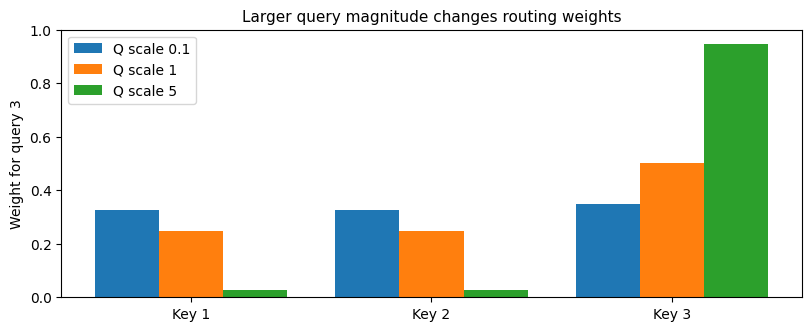

In [14]:
# Change these controls and rerun this cell; baseline Q,K,V stay unchanged.
query_index=2                 # 0,1,2 correspond to Query 1,2,3.
q_scales=[.1,1.,5.]
value_gain=1.
assert query_index in range(3) and all(scale>0 for scale in q_scales)
fig,ax=plt.subplots(figsize=(8,3.2),layout="constrained")
positions=np.arange(3)
width=.8/len(q_scales)
for i,scale in enumerate(q_scales):
    weights,outputs=attention_numpy(Q*scale,K,V*value_gain)
    ax.bar(positions+(i-(len(q_scales)-1)/2)*width,weights[query_index],width,
           label=f"Q scale {scale:g}")
    print(f"Q scale={scale:g}: weights={weights[query_index]}, output={outputs[query_index]}")
ax.set_xticks(positions,["Key 1","Key 2","Key 3"])
ax.set_ylim(0,1)
ax.set_ylabel(f"Weight for query {query_index+1}")
ax.set_title("Larger query magnitude changes routing weights",fontsize=11)
ax.legend()
fig.savefig(ASSETS/"attention_query_scaling.png",dpi=150)
plt.show()

## 9. 多头Attention：384怎样分成6个头

这份Small实现选择$C=384$、头数$h=6$，每头宽度为：

$$
d_k=d_v=C/h=64.
$$

这说明这组配置相互兼容，不说明384只能由“6×64”决定，更不说明所有Attention都必须用64维的头。

每个头可以从完整输入特征中学习自己的Q/K/V投影，在自己的表示子空间中计算关联。**不是将图像划成6块区域，也不是每个头只看6分之一的token。**

忽略batch时，单个头输出$N\times64$；将6个头沿特征轴拼接为$N\times384$，再经过输出投影$W_O$混合各头信息。拼接不是将六个输出直接求平均。

实际代码将三组投影合并为一个Linear，先得到`[B,N,3C]`，再reshape拆为Q/K/V及各头。对于包含CLS的Small方图例子：

| 位置 | 形状 |
|---|---|
| 输入token | `[1,1370,384]` |
| 联合QKV投影 | `[1,1370,1152]` |
| 每组Q/K/V拆为6头后 | `[1,6,1370,64]` |
| 每头关联权重 | `[1,6,1370,1370]` |
| 多头拼接并输出投影 | `[1,1370,384]` |

这份实现采用等宽头并拼接回C，所以C必须能被h整除。不能将这种具体实现的约束理解成所有注意力机制唯一允许的维度设计。

### 带batch/head轴时，怎样写$K^T$

数学式中的转置只针对每个头的最后两个矩阵轴。例如$K$形状为`[B,h,N,d_k]`，所需转置形状是`[B,h,d_k,N]`。

```python
# NumPy：交换最后两个轴，保留batch/head
scores = q @ np.swapaxes(k, -2, -1)
# PyTorch：同样只交换最后两个轴
scores = q @ k.transpose(-2, -1)
```

NumPy数组的`.T`会逆序全部轴：对二维矩阵它恰好是所需转置，对四维数组却会把batch/head位置也改变。Notebook从单头推广到多头时要明确这一点，不能把二维代码不加检查地搬过去。

In [15]:
rng_heads=np.random.default_rng(19)
B_multi,N_multi,C_multi,H_multi=1,3,4,2
d_head=C_multi//H_multi
X_multi=rng_heads.normal(size=(B_multi,N_multi,C_multi))
Wq_multi,Wk_multi,Wv_multi,Wo_multi=[rng_heads.normal(size=(4,4)) for _ in range(4)]
q_flat,k_flat,v_flat=[X_multi@w for w in [Wq_multi,Wk_multi,Wv_multi]]
joint=np.concatenate([q_flat,k_flat,v_flat],axis=-1)
split=joint.reshape(B_multi,N_multi,3,H_multi,d_head).transpose(2,0,3,1,4)
qh,kh,vh=split
weights_heads,output_heads=attention_numpy(qh,kh,vh)
joined=output_heads.transpose(0,2,1,3).reshape(B_multi,N_multi,C_multi)
output_multi=joined@Wo_multi
torch_heads=F.scaled_dot_product_attention(*[torch.tensor(a,dtype=torch.float64) for a in [qh,kh,vh]],dropout_p=0.)
torch_multi=torch_heads.transpose(1,2).reshape(1,3,4)@torch.tensor(Wo_multi,dtype=torch.float64)
multi_head_error=float(np.max(np.abs(output_multi-torch_multi.numpy())))
assert qh.shape==(1,2,3,2) and weights_heads.shape==(1,2,3,3)
assert joined.shape==output_multi.shape==(1,3,4)
assert np.allclose(output_multi,torch_multi.numpy(),rtol=1e-11,atol=1e-11)
print("Joint QKV:",joint.shape,"per-head Q:",qh.shape,"weights:",weights_heads.shape)
print("Concatenated:",joined.shape,"projected output:",output_multi.shape)
print("NumPy / Torch multihead max difference:",multi_head_error)

Joint QKV: (1, 3, 12) per-head Q: (1, 2, 3, 2) weights: (1, 2, 3, 3)
Concatenated: (1, 3, 4) projected output: (1, 3, 4)
NumPy / Torch multihead max difference: 8.881784197001252e-16


## 10. Attention在完整网络中的位置

Attention输出的是更新后的token特征。实际Transformer块还包含LayerNorm、残差、LayerScale和MLP。MLP逐位置处理特征通道，Attention负责位置间的信息交换。

位置编码提供顺序/位置线索；没有位置线索的纯self-attention具有序列重排等变性，Notebook会核对这一性质。CLS是额外的可学习token，不是一个真实图像patch，也不是已给定的类别标签。

在Depth Anything V2中，编码器选取的四层patch特征仍是同一网格；DPT接着将它们重排为二维图、调整尺度并融合，最后输出一个逐像素标量。Attention本身没有自动把1369个patch变成518×518个像素，更没有自动赋予输出米制单位。

连接：[Depth Anything V2网络结构](../../02_papers/depth_estimation/Depth_Anything_V2_zh/network_structure.md)、[当前阅读笔记](../../02_papers/depth_estimation/Depth_Anything_V2_zh/reading_notes.md)。

In [16]:
# Optional direct comparison with the previously pinned official Attention class.
manifest_path=WORKSPACE_DIR/"02_papers/depth_estimation/Depth_Anything_V2_zh/network_source_manifest.json"
reference_check={"status":"not_run_source_missing"}
if manifest_path.is_file():
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    relative="depth_anything_v2/dinov2_layers/attention.py"
    source=WORKSPACE_DIR/manifest["source_cache"]/relative
    if source.is_file():
        expected=next(item["sha256"] for item in manifest["files"] if item["path"]==relative)
        assert hashlib.sha256(source.read_bytes()).hexdigest()==expected
        spec=importlib.util.spec_from_file_location("attention_foundations_reference",source)
        module=importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)
        reference=module.Attention(dim=2,num_heads=1,qkv_bias=False,proj_bias=False).double().eval()
        with torch.no_grad():
            reference.qkv.weight.copy_(torch.tensor(np.concatenate([WQ.T,WK.T,WV.T],axis=0)))
            reference.proj.weight.copy_(torch.eye(2,dtype=torch.float64))
            actual=reference(torch.tensor(X,dtype=torch.float64)[None])[0].numpy()
        error=float(np.max(np.abs(actual-O)))
        assert np.allclose(actual,O,rtol=1e-12,atol=1e-12)
        reference_check={"status":"pass","commit":manifest["commit"],"max_abs_difference":error}
print("Pinned official Attention comparison:",reference_check)

xFormers not available


Pinned official Attention comparison: {'status': 'pass', 'commit': 'a561b849ebae10a6f5ef49e26c83cbbcd36c71bf', 'max_abs_difference': 8.881784197001252e-16}


## 11. 运行、核验与练习

从工作区根目录启动本机已有环境：

```powershell
& 'D:\Conda\envs\torch_gpu_py310\python.exe' -m notebook '01_foundations/learning/token_embedding_attention.ipynb'
```

Notebook按“解释→代码→结果→修改练习”组织。它核对手算矩阵、Conv2d与逐patch线性投影、NumPy与PyTorch Attention、单头与多头形状及若干性质；所有数值都属于合成教学例子。

先完成以下自测，再回到论文网络：

- [ ] 为什么同一个patch可以输出2维、3维或384维向量？哪些数字是架构设置，哪些数值是学习结果？
- [ ] token数量N与特征维度C分别表示什么？
- [ ] 为什么需要Q和K计算权重，再用权重组合V？
- [ ] $QK^T$的行、列分别是什么，softmax沿哪一维？
- [ ] 3个二维token经过单头Attention后，为何仍是3个token？
- [ ] 6个头拼接后的384维，为什么不代表6种深度或6块图像？

源码与原始方法入口：

- [固定官方Small宽度及其他配置](https://github.com/DepthAnything/Depth-Anything-V2/blob/a561b849ebae10a6f5ef49e26c83cbbcd36c71bf/depth_anything_v2/dinov2.py#L339-L415)。
- [固定官方Attention实现](https://github.com/DepthAnything/Depth-Anything-V2/blob/a561b849ebae10a6f5ef49e26c83cbbcd36c71bf/depth_anything_v2/dinov2_layers/attention.py#L29-L62)。
- [Attention Is All You Need，§3.2.1—3.2.2](https://arxiv.org/html/1706.03762v7#S3.SS2)：缩放点积和多头计算。
- [ViT，§3.1](https://arxiv.org/html/2010.11929v2#S3.SS1)：图像patch的可学习线性嵌入。

术语与公式为基础教学整理，未将新材料的生成或算例通过判定为本人已掌握。

In [17]:
report={
    "example_kind":"synthetic_foundations_no_pretrained_depth_model",
    "date":"2026-11-14",
    "environment":{"python":sys.version.split()[0],"executable":sys.executable,"numpy":np.__version__,"torch":torch.__version__,"matplotlib":matplotlib.__version__,"device":"cpu"},
    "projection":{"input":x_patch.tolist(),"C2":t2.tolist(),"C3":t3.tolist(),"conv_token_shape":list(conv_tokens.shape),"conv_linear_max_abs_difference":projection_max_error,"patch_layer_parameters":226176},
    "toy_gradient":{"loss_before":float(loss_before.detach()),"loss_after":float(loss_after),"output_after":pred_updated.tolist()},
    "attention":{"Q":Q.tolist(),"K":K.tolist(),"V":V.tolist(),"S":S.tolist(),"A":A.tolist(),"O":O.tolist(),"torch_sdpa_max_abs_difference":single_head_error},
    "variance_examples":variance_examples,
    "properties":{"row_sums_one":True,"row_shift_invariance":True,"V_changes_content_not_weights":True,"constant_V_gives_constant_output":True,"permutation_equivariance_without_position":True},
    "multihead":{"C":4,"heads":2,"joint_qkv_shape":list(joint.shape),"head_shape":list(qh.shape),"output_shape":list(output_multi.shape),"torch_max_abs_difference":multi_head_error},
    "official_attention_comparison":reference_check,
    "exercise_settings":{"query_index":query_index,"q_scales":q_scales,"value_gain":value_gain},
    "figures":["assets/attention_scores_weights.png","assets/attention_query_scaling.png"],
    "status":"pass"
}
receipt=MATERIAL_DIR/"token_attention_verification.json"
receipt.write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding="utf-8")
print("PASS: all executed numerical assertions; receipt:",receipt)

PASS: all executed numerical assertions; receipt: D:\Xuxp\slam-2028-prep\01_foundations\learning\token_attention_verification.json
